# 04 — Features and preprocessing

## Goal of this step

Express six business hypotheses as deterministic features. Build an unfitted preprocessor suitable for honest cross-validation and future customers.

## Why this matters

Features are like translating a story into clues a model can read. A pipeline is a sealed recipe: each training fold prepares its own ingredients rather than borrowing knowledge from validation customers.

Find the project root and import display tools. Reusable logic lives in src.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np  # noqa: F401
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
plt.rcParams["figure.figsize"] = (8, 4)


Create row-local features using pandas and numpy; the target is never an input.

In [2]:
from src.split import training_frame
from src.features import add_features, make_preprocessor, plot_feature, run_features
df = training_frame()
engineered = add_features(df)
display(engineered.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_bucket,avg_monthly_spend,charge_ratio,num_services,is_autopay,has_support_bundle
2624,Male,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,Credit card (automatic),70.70,140.70,0-12,70.350000,0.995050,2,1,0
2645,Female,0,No,No,15,Yes,Yes,Fiber optic,Yes,No,...,Yes,Credit card (automatic),84.35,1302.65,13-24,86.843333,1.029559,5,1,0
1416,Male,0,Yes,Yes,67,Yes,Yes,Fiber optic,No,Yes,...,Yes,Bank transfer (automatic),89.55,6373.10,49+,95.120896,1.062210,5,1,0
5760,Male,0,No,No,5,Yes,No,DSL,No,Yes,...,Yes,Bank transfer (automatic),65.60,339.90,0-12,67.980000,1.036280,5,1,0
2420,Male,0,No,No,26,Yes,No,No,No,No,...,Yes,Electronic check,20.30,511.25,25-48,19.663462,0.968643,1,0,0


**Interpretation:** Each customer gains six business representations; no population statistics were learned.

**tenure_bucket:** Fixed 0-12, 13-24, 25-48, 49+ month groups express customer lifecycle. Compare churn rates using training rows.

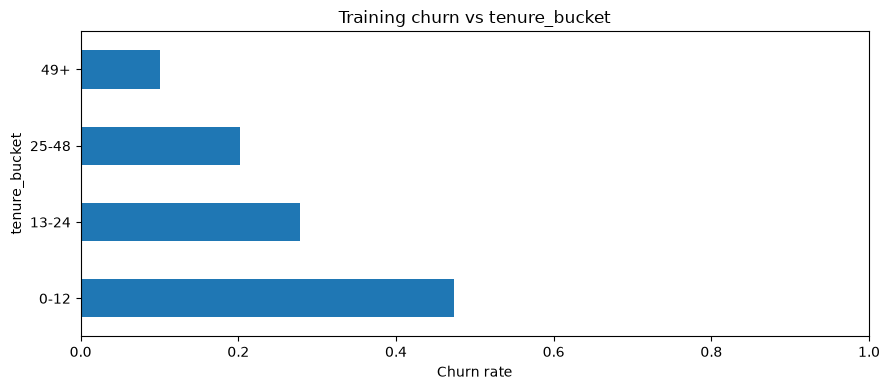

,customers,churn_rate
tenure_bucket,,
0-12,1728,0.473380
13-24,824,0.277913
25-48,1282,0.202028
49+,1782,0.100449


In [3]:
display(plot_feature(df, 'tenure_bucket', show=True))

**Interpretation:** Differences suggest possible predictive value; correlated features may add little beyond the original columns. CV, rather than this plot, decides usefulness.

**avg_monthly_spend:** TotalCharges / tenure summarizes historical spending; at zero tenure use the current monthly plan as a proxy. Compare churn rates using training rows.

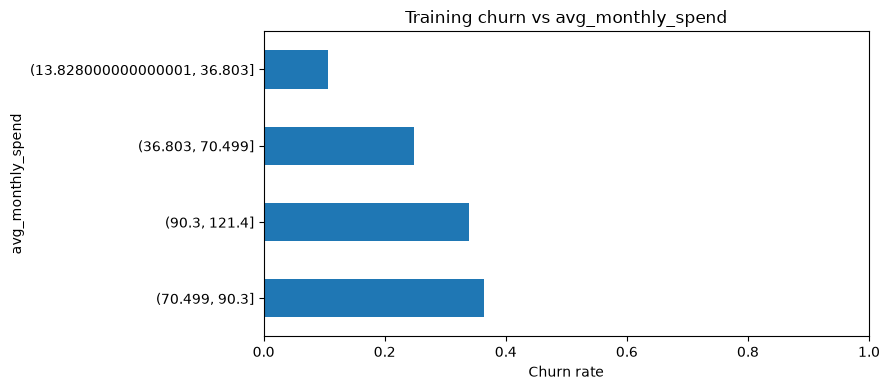

,customers,churn_rate
avg_monthly_spend,,
"(70.499, 90.3]",1404,0.363960
"(90.3, 121.4]",1404,0.339031
"(36.803, 70.499]",1404,0.247863
"(13.828000000000001, 36.803]",1404,0.106838


In [4]:
display(plot_feature(df, 'avg_monthly_spend', show=True))

**Interpretation:** Differences suggest possible predictive value; correlated features may add little beyond the original columns. CV, rather than this plot, decides usefulness.

**charge_ratio:** TotalCharges / (MonthlyCharges * tenure) compares historical bills with today's plan; at zero tenure use neutral 1. This is a noisy proxy, not verified price change. Compare churn rates using training rows.

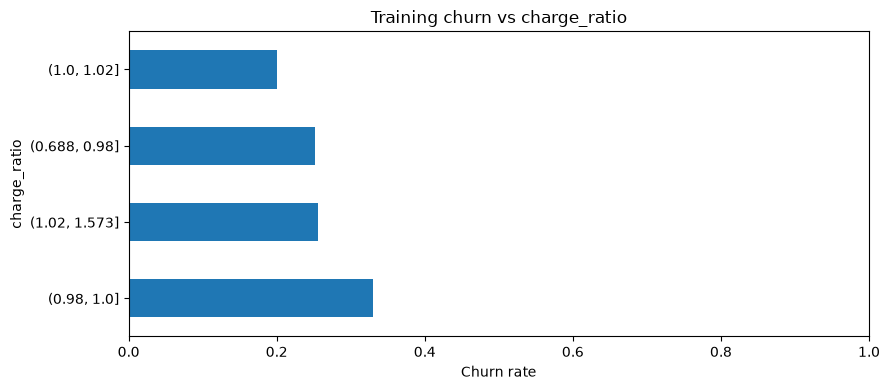

,customers,churn_rate
charge_ratio,,
"(0.98, 1.0]",1604,0.330424
"(1.02, 1.573]",1404,0.256410
"(0.688, 0.98]",1404,0.251425
"(1.0, 1.02]",1204,0.200997


In [5]:
display(plot_feature(df, 'charge_ratio', show=True))

**Interpretation:** Differences suggest possible predictive value; correlated features may add little beyond the original columns. CV, rather than this plot, decides usefulness.

**num_services:** Count phone, extra lines, internet, and six add-ons (0-9); bundle breadth may reflect engagement. Compare churn rates using training rows.

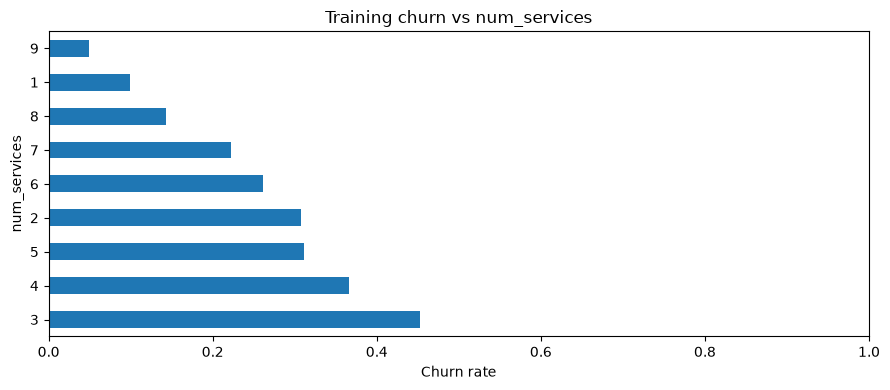

,customers,churn_rate
num_services,,
3,663,0.452489
4,773,0.366106
5,732,0.311475
2,674,0.307122
6,731,0.261286
7,552,0.222826
8,315,0.142857
1,1012,0.098814
9,164,0.048780


In [6]:
display(plot_feature(df, 'num_services', show=True))

**Interpretation:** Differences suggest possible predictive value; correlated features may add little beyond the original columns. CV, rather than this plot, decides usefulness.

**is_autopay:** Automatic bank/card payments may reflect convenience and payment habits. Compare churn rates using training rows.

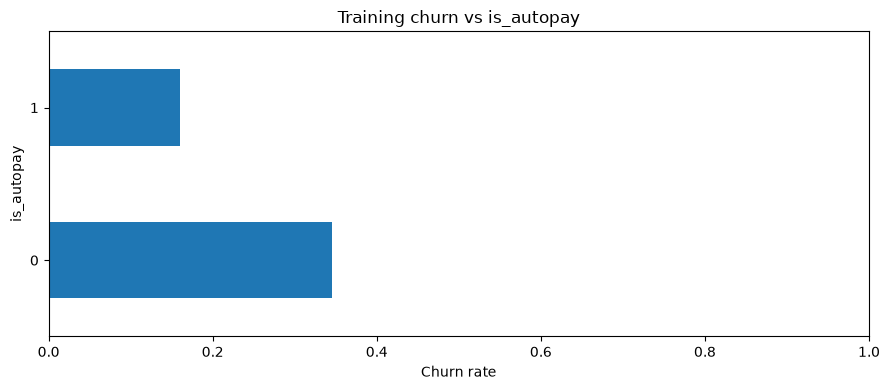

,customers,churn_rate
is_autopay,,
0,3174,0.344991
1,2442,0.159705


In [7]:
display(plot_feature(df, 'is_autopay', show=True))

**Interpretation:** Differences suggest possible predictive value; correlated features may add little beyond the original columns. CV, rather than this plot, decides usefulness.

**has_support_bundle:** Both OnlineSecurity and TechSupport may indicate a supported service experience. Compare churn rates using training rows.

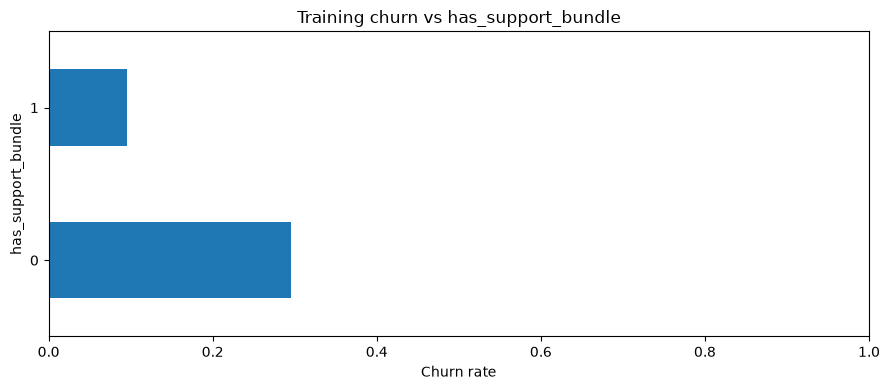

,customers,churn_rate
has_support_bundle,,
0,4746,0.295407
1,870,0.095402


In [8]:
display(plot_feature(df, 'has_support_bundle', show=True))

**Interpretation:** Differences suggest possible predictive value; correlated features may add little beyond the original columns. CV, rather than this plot, decides usefulness.

Median imputation fills unknown numeric values; scaling puts numeric values on comparable units. One-hot encoding makes category indicator columns and ignores unseen categories. Fit this demonstration on training only; real model CV creates a fresh preprocessor inside each fold.

In [9]:
pre = make_preprocessor()
transformed = pre.fit_transform(engineered)
display(pd.Series({'rows': transformed.shape[0], 'columns': transformed.shape[1], 'finite': bool(np.isfinite(transformed).all())}))
display(pd.Series(pre.get_feature_names_out(), name='encoded_columns'))
run_features()

rows       5616
columns      47
finite     True
dtype: object

0                               num__SeniorCitizen
1                                      num__tenure
2                              num__MonthlyCharges
3                                num__TotalCharges
4                           num__avg_monthly_spend
5                                num__charge_ratio
6                                num__num_services
7                                  num__is_autopay
8                          num__has_support_bundle
9                               cat__gender_Female
10                                cat__gender_Male
11                                 cat__Partner_No
12                                cat__Partner_Yes
13                              cat__Dependents_No
14                             cat__Dependents_Yes
15                            cat__PhoneService_No
16                           cat__PhoneService_Yes
17                           cat__MultipleLines_No
18                          cat__MultipleLines_Yes
19                        cat__

{'training_rows': 5616, 'output_columns': 47, 'finite': True}

**Interpretation:** The fitted transformer yields a finite matrix with a fixed output schema for future rows. Different training folds can discover different category vocabularies; stability means transform does not change a fitted schema.

## Common mistakes

- Fitting a scaler or median on test data.
- Dividing by zero tenure.
- Assuming feature churn plots establish incremental value or causality.

## Key takeaways

- Six features have explicit business meanings and zero-denominator rules.
- The target and ID are excluded from model inputs.
- Imputation, scaling, and encoding will stay inside each CV pipeline.

## Next step

05_split_and_baseline.ipynb: establish a simple, honest reference score.